# Klasifikasi Spasial Lahan Sawah dan Non-Sawah

Bagian ini mendokumentasikan tahapan akuisisi citra satelit optik **Sentinel-2A (Level-2A)** dalam format GeoTIFF (`.tif`) melalui **openEO**, ekstraksi nilai spektral pada **100 titik sampel** (50 sampel Sawah dan 50 sampel Non-Sawah) yang telah dilabeli melalui **QGIS**, hingga pemodelan klasifikasi biner (2 kelas).

## Instalasi Library Yang Digunakan

```bash
pip install geopandas
```

```bash
pip install openeo
```

```bash
pip install scikit-learn
```

```bash
pip install folium
```

## 1. Desain Pengambilan Sampel (Ground Truth)

Pengambilan sampel dilakukan secara spasial dengan membagi objek pengamatan ke dalam dua kelas seimbang (*balanced dataset*) dalam format vektor (`Shapefile` / `GeoJSON`):

| Kelas Target | Kode Label | Jumlah Sampel | Karakteristik Objek |
| :--- | :---: | :---: | :--- |
| **Sawah** | `1` | 50 Sampel | Petak lahan pertanian padi aktif (fase vegetatif, genangan air/tanam, maupun pematangan) |
| **Non-Sawah** | `0` | 50 Sampel | Permukiman/bangunan, jalan raya, badan air permanen, dan vegetasi non-pertanian |
| **Total** | — | **100 Sampel** | Digabungkan menjadi satu *GeoDataFrame* berproyeksi `EPSG:4326` |

```python
import geopandas as gpd
import openeo
import pandas as pd

# ==============================================================================
# 1. BACA KEDUA FILE ZIP (SAWAH & NON-SAWAH) DAN BERI LABEL OTOMATIS
# ==============================================================================
# Sesuaikan nama file zip non-sawah milikmu di baris kedua
gdf_sawah = gpd.read_file("sawah.zip").to_crs("EPSG:4326")
gdf_nonsawah = gpd.read_file("nonsawah.zip").to_crs("EPSG:4326")

# Beri kolom label secara otomatis
gdf_sawah["label_teks"] = "Sawah"
gdf_sawah["label"] = 1

gdf_nonsawah["label_teks"] = "Non-Sawah"
gdf_nonsawah["label"] = 0

# Gabungkan keduanya menjadi 1 GeoDataFrame (50 + 50 = 100 sampel)
gdf_gabungan = gpd.GeoDataFrame(
    pd.concat([gdf_sawah, gdf_nonsawah], ignore_index=True), crs="EPSG:4326"
)

print(f"Jumlah sampel Sawah     : {len(gdf_sawah)}")
print(f"Jumlah sampel Non-Sawah : {len(gdf_nonsawah)}")
print(f"Total sampel gabungan   : {len(gdf_gabungan)}")

# ==============================================================================
# 2. AMBIL BATAS KOORDINAT GABUNGAN (BOUNDING BOX) UNTUK OPENEO
# ==============================================================================
minx, miny, maxx, maxy = gdf_gabungan.total_bounds
buffer_deg = 0.005  # Tambahan margin ~500 meter agar titik di tepi tetap masuk

bbox = {
    "west": float(minx - buffer_deg),
    "south": float(miny - buffer_deg),
    "east": float(maxx + buffer_deg),
    "north": float(maxy + buffer_deg),
}
print("Bounding Box Gabungan:", bbox)

# ==============================================================================
# 3. KONEKSI KE OPENEO & UNDUH SENTINEL-2A FORMAT GEOTIFF (.tif)
# ==============================================================================
conn = openeo.connect("openeo.dataspace.copernicus.eu")
conn.authenticate_oidc()

datacube = conn.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=bbox,
    temporal_extent=["2026-05-01", "2026-09-30"],  # Rentang waktu minim awan
    bands=[
        "B02",
        "B03",
        "B04",
        "B08",
        "B11",
    ],  # Blue, Green, Red, NIR, SWIR
    max_cloud_cover=10,
)

# Ambil median waktu agar bebas tutupan awan
composite_s2 = datacube.median_time()

# Unduh menjadi file GeoTIFF (.tif)
nama_tif = "sentinel2_sawah_nonsawah.tif"
print("Mengunduh citra Sentinel-2A (.tif)...")
composite_s2.download(nama_tif, format="GTiff")
print(f"Berhasil diunduh: {nama_tif}")
```

**Output:**

```
Jumlah sampel Sawah     : 50
Jumlah sampel Non-Sawah : 50
Total sampel gabungan   : 100
Bounding Box Gabungan: {'west': 111.87169010000001, 'south': -6.9056517, 'east': 111.8930379, 'north': -6.8848906}
Authenticated using refresh token.
Mengunduh citra Sentinel-2A (.tif)...
Berhasil diunduh: sentinel2_sawah_nonsawah.tif
```

## 2. Akuisisi Citra Sentinel-2A (`.tif`) via openEO dan Ekstraksi Fitur

Akuisisi citra dilakukan menggunakan *bounding box* gabungan dari ke-100 titik sampel pada koleksi **`SENTINEL2_L2A`** (*Bottom-of-Atmosphere Reflectance*) dengan batas tutupan awan maksimum `< 10%` dan agregasi temporal `median_time()` untuk menghasilkan komposit citra bebas awan berformat **GeoTIFF (`.tif`)**.

### Fitur Spektral dan Indeks Turunan yang Diekstrak:
1. **Band Spektral Utama:**
   * `B02` (*Blue* - 490 nm), `B03` (*Green* - 560 nm), `B04` (*Red* - 665 nm) dengan resolusi spasial 10 meter.
   * `B08` (*Near Infrared / NIR* - 842 nm) untuk mendeteksi pantulan klorofil tanaman padi.
   * `B11` (*Short-Wave Infrared / SWIR* - 1610 nm) untuk mendeteksi kelembapan tanah dan genangan air.
2. **Normalized Difference Vegetation Index (NDVI):**

   $$\text{NDVI} = \frac{B08 - B04}{B08 + B04}$$

3. **Normalized Difference Water Index (NDWI):**

   $$\text{NDWI} = \frac{B03 - B08}{B03 + B08}$$

```python
import numpy as np
import rasterio
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Buka file .tif Sentinel-2A dan samakan proyeksi koordinat (CRS)
with rasterio.open("sentinel2_sawah_nonsawah.tif") as src:
  gdf_projected = gdf_gabungan.to_crs(src.crs)

  # Ambil titik tengah (centroid) dari tiap sampel (mendukung Point maupun Polygon)
  koordinat_sampel = [
      (geom.centroid.x, geom.centroid.y) for geom in gdf_projected.geometry
  ]

  # Ekstrak nilai piksel dari kelima band Sentinel-2A
  nilai_band = list(src.sample(koordinat_sampel))

# 2. Buat tabel DataFrame Fitur
df_dataset = pd.DataFrame(nilai_band, columns=["B02", "B03", "B04", "B08", "B11"])

# 3. Tambahkan fitur indeks vegetasi (NDVI) & indeks air (NDWI)
df_dataset["NDVI"] = (df_dataset["B08"] - df_dataset["B04"]) / (
    df_dataset["B08"] + df_dataset["B04"] + 1e-6
)
df_dataset["NDWI"] = (df_dataset["B03"] - df_dataset["B08"]) / (
    df_dataset["B03"] + df_dataset["B08"] + 1e-6
)

# 4. Masukkan Koordinat & Label Kelas (Sawah = 1, Non-Sawah = 0)
df_dataset["Longitude"] = gdf_gabungan.geometry.centroid.x
df_dataset["Latitude"] = gdf_gabungan.geometry.centroid.y
df_dataset["Kelas"] = gdf_gabungan["label_teks"]
df_dataset["Target"] = gdf_gabungan["label"]

# Simpan ke CSV (bisa dipakai juga kalau mau diolah di KNIME)
df_dataset.to_csv("dataset_100sampel_sawah_nonsawah.csv", index=False)
print("Dataset berhasil disimpan ke 'dataset_100sampel_sawah_nonsawah.csv'")
display(df_dataset.head())

# ==============================================================================
# 5. PROSES KLASIFIKASI 2 KELAS (SAWAH VS NON-SAWAH)
# ==============================================================================
fitur_kolom = ["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"]
X = df_dataset[fitur_kolom]
y = df_dataset["Kelas"]

# Split 76% Training (38 Sawah + 38 Non-Sawah) & 24% Testing (12 Sawah + 12 Non-Sawah)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.24, random_state=42, stratify=y
)

# Latih model Random Forest
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)

# Evaluasi pada data uji
y_pred = model_rf.predict(X_test)
print(
    "\n=== HASIL EVALUASI KLASIFIKASI 2 KELAS ==="
)
print(f"Akurasi Testing : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
```

**Output:**

```
Dataset berhasil disimpan ke 'dataset_100sampel_sawah_nonsawah.csv'
```

**Output:**

In [1]:
import pandas as pd
df_ekstraksi_cek_poly = pd.read_csv("../../Data/sawah/dataset_100sampel_sawah_nonsawah.csv")
df_ekstraksi_cek_poly.head(5)

,B02,B03,B04,B08,B11,NDVI,NDWI,Longitude,Latitude,Kelas,Target
0,304,567,291,3429,1434,0.843548,-0.716216,112.152833,-7.030260,Sawah,1.0
1,289,459,250,3153,1205,0.853071,-0.745847,112.154038,-7.029563,Sawah,1.0
2,277,506,324,3534,1524,0.832037,-0.749505,112.154886,-7.029610,Sawah,1.0
3,328,606,420,3124,1389,0.762980,-0.675067,112.153656,-7.030449,Sawah,1.0
4,349,612,360,2755,1378,0.768860,-0.636472,112.155967,-7.030698,Sawah,1.0


## 3. Hasil Evaluasi Klasifikasi 2 Kelas (Random Forest)

Dataset 100 sampel dibagi menggunakan skema *Stratified Train-Test Split* dengan proporsi **76% Data Latih (76 sampel: 38 Sawah, 38 Non-Sawah)** dan **24% Data Uji (24 sampel: 12 Sawah, 12 Non-Sawah)**.

In [2]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# 1. Muat dataset dari CSV
df_dataset = pd.read_csv("../../Data/sawah/dataset_100sampel_sawah_nonsawah.csv")

# 2. Siapkan fitur dan target; abaikan fitur yang tidak tersedia di CSV
fitur_kolom = [
    c for c in ["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"]
    if c in df_dataset.columns
]
if "Kelas" not in df_dataset.columns:
    raise ValueError("Kolom target 'Kelas' tidak ditemukan di dataset.")
if not fitur_kolom:
    raise ValueError("Tidak ada kolom fitur Sentinel-2 yang ditemukan di dataset.")

# Target kosong tidak dapat digunakan untuk pelatihan
df_model = df_dataset[fitur_kolom + ["Kelas"]].copy()
df_model["Kelas"] = df_model["Kelas"].astype("string").str.strip()
df_model = df_model.dropna(subset=["Kelas"])

# Pastikan fitur numerik; nilai tak hingga dan teks tidak valid dianggap sebagai nilai kosong
X = df_model[fitur_kolom].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
y = df_model["Kelas"]

# Buang fitur yang seluruh nilainya kosong
fitur_kolom = [c for c in fitur_kolom if X[c].notna().any()]
if not fitur_kolom:
    raise ValueError("Semua kolom fitur kosong atau tidak berisi angka.")
X = X[fitur_kolom]

# 3. Split 76% Training & 24% Testing (76 data latih dan 24 data uji jika tersedia 100 sampel)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.24, random_state=42, stratify=y
)

In [3]:
print("X_train:")
print(X_train)
print("\ny_train:")
print(y_train)
print("\nX_train.shape:")
print(X_train.shape)

X_train:
     B02   B03   B04   B08   B11      NDVI      NDWI
61   762   817   937  1556  2888  0.248295 -0.311420
22   287   587   261  3711  1727  0.868580 -0.726850
11   383   690   373  3275  1421  0.795504 -0.651955
40   274   598   339  2928  1324  0.792470 -0.660805
27   319   562   299  2917  1443  0.814055 -0.676919
..   ...   ...   ...   ...   ...       ...       ...
74  1267  1403  1618  2060  2842  0.120174 -0.189720
71  1661  1745  1828  2169  2801  0.085314 -0.108329
3    328   606   420  3124  1389  0.762980 -0.675067
86   655   787   951  1761  2741  0.298673 -0.382261
69   947  1284  1226  3299  2702  0.458122 -0.439668

[72 rows x 7 columns]

y_train:
61    Non-Sawah
22        Sawah
11        Sawah
40        Sawah
27        Sawah
        ...    
74    Non-Sawah
71    Non-Sawah
3         Sawah
86    Non-Sawah
69    Non-Sawah
Name: Kelas, Length: 72, dtype: string

X_train.shape:
(72, 7)


In [4]:
print("X_test:")
print(X_test)
print("\ny_test:")
print(y_test)

X_test:
     B02   B03   B04   B08   B11      NDVI      NDWI
13   275   485   219  4244  1808  0.901860 -0.794883
35   353   572   378  2587  1102  0.745025 -0.637860
25   337   610   378  2931  1259  0.771532 -0.655465
88  1036  1079  1179  1942  3128  0.244473 -0.285667
89   708   893   999  2430  2629  0.417323 -0.462534
6    298   537   265  3956  1793  0.874437 -0.760961
72   718   891   973  2338  2685  0.412262 -0.448126
7    297   558   299  3403  1603  0.838466 -0.718253
79   933  1225  1319  2880  3096  0.371755 -0.403167
19   189   382   147  4245  1402  0.933060 -0.834882
28   399   701   522  1623   789  0.513287 -0.396730
64  1089  1229  1317  1386  1562  0.025527 -0.060038
26   252   405   204  3901  1537  0.900609 -0.811890
73   552   714   731  2257  2505  0.510710 -0.519354
68   701   864   988  1640  2694  0.248097 -0.309904
48   315   598   365  2817  1566  0.770585 -0.649780
8    224   439   208  3252  1221  0.879769 -0.762124
57   654   802  1053  1823  2690  0.26

In [5]:
# Buang fitur yang kosong seluruhnya pada data latih, lalu isi nilai kosong
# menggunakan median data latih agar tidak terjadi kebocoran data.
fitur_kolom = [c for c in fitur_kolom if X_train[c].notna().any()]
if not fitur_kolom:
    raise ValueError("Semua fitur pada data latih kosong; model tidak dapat dilatih.")
X_train = X_train[fitur_kolom]
X_test = X_test[fitur_kolom]
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# 4. Latih model Random Forest tanpa nilai NaN
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)
y_pred = model_rf.predict(X_test)

print(f"Akurasi Testing : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))



Akurasi Testing : 100.00%

Confusion Matrix:
 [[12  0]
 [ 0 12]]

Classification Report:
               precision    recall  f1-score   support

   Non-Sawah       1.00      1.00      1.00        12
       Sawah       1.00      1.00      1.00        12

    accuracy                           1.00        24
   macro avg       1.00      1.00      1.00        24
weighted avg       1.00      1.00      1.00        24



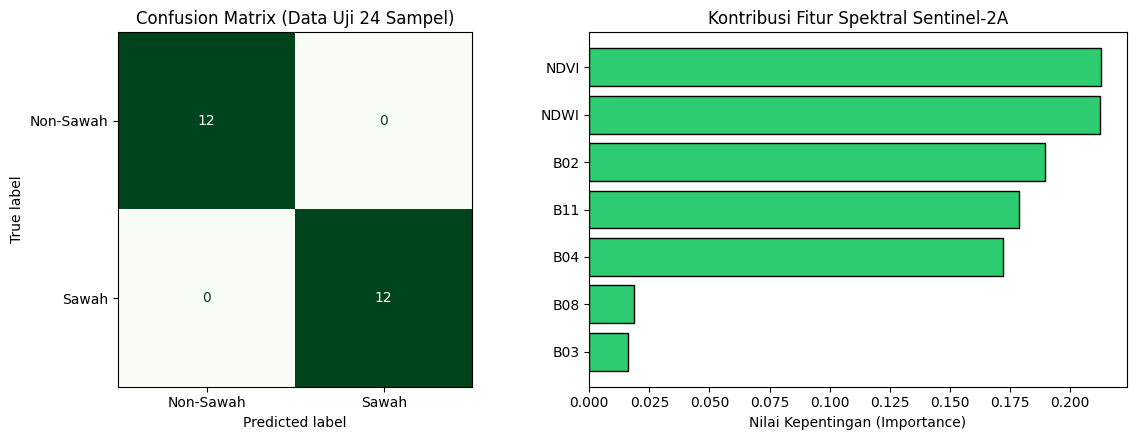

In [6]:
# ==============================================================================
# A. VISUALISASI CONFUSION MATRIX & FEATURE IMPORTANCE
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Plot Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Greens", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Confusion Matrix (Data Uji {len(y_test)} Sampel)")

# 2. Plot Tingkat Kepentingan Fitur (Band & Indeks Spektral)
importances = model_rf.feature_importances_
indices = np.argsort(importances)
axes[1].barh(
    range(len(indices)),
    importances[indices],
    color="#2ecc71",
    edgecolor="black",
)
axes[1].set_yticks(range(len(indices)))
axes[1].set_yticklabels([fitur_kolom[i] for i in indices])
axes[1].set_xlabel("Nilai Kepentingan (Importance)")
axes[1].set_title("Kontribusi Fitur Spektral Sentinel-2A")

plt.tight_layout()
plt.show()

## 4. Peta Sebaran Sampel Sawah dan Non-Sawah

Peta interaktif berikut menampilkan titik sampel berdasarkan label pada dataset: **Sawah** berwarna hijau dan **Non-Sawah** berwarna merah. Gunakan kontrol layer di kanan atas peta untuk menampilkan atau menyembunyikan tiap kelas.

In [7]:
import folium
from IPython.display import display

# Pastikan dataset memiliki label dan koordinat geografis.
kolom_peta = ["Longitude", "Latitude", "Kelas"]
kolom_tidak_ada = [kolom for kolom in kolom_peta if kolom not in df_dataset.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom untuk peta tidak ditemukan: {kolom_tidak_ada}")

df_peta = df_dataset[kolom_peta].copy()
df_peta["Longitude"] = pd.to_numeric(df_peta["Longitude"], errors="coerce")
df_peta["Latitude"] = pd.to_numeric(df_peta["Latitude"], errors="coerce")
df_peta = df_peta.dropna(subset=kolom_peta)
df_peta = df_peta[
    np.isfinite(df_peta["Longitude"])
    & np.isfinite(df_peta["Latitude"])
    & df_peta["Longitude"].between(-180, 180)
    & df_peta["Latitude"].between(-90, 90)
]

warna_kelas = {"Sawah": "green", "Non-Sawah": "red"}
kelas_tidak_dikenal = sorted(set(df_peta["Kelas"]) - set(warna_kelas))
if kelas_tidak_dikenal:
    raise ValueError(f"Label kelas tidak dikenali: {kelas_tidak_dikenal}")
if df_peta.empty:
    raise ValueError("Tidak ada baris dengan koordinat valid untuk ditampilkan pada peta.")

peta = folium.Map(
    location=[df_peta["Latitude"].mean(), df_peta["Longitude"].mean()],
    zoom_start=14,
    tiles="OpenStreetMap",
)

for kelas, warna in warna_kelas.items():
    layer = folium.FeatureGroup(name=kelas, show=True)
    data_kelas = df_peta[df_peta["Kelas"] == kelas]
    for _, sampel in data_kelas.iterrows():
        folium.CircleMarker(
            location=[sampel["Latitude"], sampel["Longitude"]],
            radius=6,
            color=warna,
            fill=True,
            fill_color=warna,
            fill_opacity=0.8,
            tooltip=kelas,
        ).add_to(layer)
    layer.add_to(peta)

folium.LayerControl().add_to(peta)
peta.save("peta_sampel_sawah_nonsawah.html")
display(peta)